In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

import time
import copy
import gc
import json

import matplotlib.pyplot as plt
import seaborn as sns
import random
import numpy as np
import pandas as pd

import torch
import torch.nn as nn

from utils import get_opt, get_loaders, eval_ppl

In [2]:
DEV = torch.device('cuda:0') if torch.cuda.is_available() else torch.device('cpu')

seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

# Load

## Model

In [11]:
# model_name = "HuggingFaceTB/SmolLM2-135M"
model_name = "HuggingFaceTB/SmolLM2-1.7B"

model = get_opt(model_name)
model.eval()
model.to(DEV)

LlamaForCausalLM(
  (model): LlamaModel(
    (embed_tokens): Embedding(49152, 2048)
    (layers): ModuleList(
      (0-23): 24 x LlamaDecoderLayer(
        (self_attn): LlamaAttention(
          (q_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (k_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (v_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (o_proj): Linear(in_features=2048, out_features=2048, bias=False)
        )
        (mlp): LlamaMLP(
          (gate_proj): Linear(in_features=2048, out_features=8192, bias=False)
          (up_proj): Linear(in_features=2048, out_features=8192, bias=False)
          (down_proj): Linear(in_features=8192, out_features=2048, bias=False)
          (act_fn): SiLU()
        )
        (input_layernorm): LlamaRMSNorm((2048,), eps=1e-05)
        (post_attention_layernorm): LlamaRMSNorm((2048,), eps=1e-05)
      )
    )
    (norm): LlamaRMSNorm((2048,), eps=1e-05)
    (rotary_emb)

## Stored results

In [4]:
# with open("results/layer_thresholds_stats.json", "r") as f:
#     layer_thresholds_stats = json.load(f)
# for i, layer in enumerate(model.model.layers):
#     layer.mlp.norm_stats_c4 = layer_thresholds_stats[str(i)]['norm_stats_c4']
#     layer.mlp.norm_stats_wiki = layer_thresholds_stats[str(i)]['norm_stats_wiki']

In [17]:
results_c4_ppl = pd.read_csv('results/results_thr_c4_ppl.csv', index_col=0)
results_c4_ratio = pd.read_csv('results/results_thr_c4_ratio.csv', index_col=0)
results_wiki_ppl = pd.read_csv('results/results_thr_wiki_ppl.csv', index_col=0)
results_wiki_ratio = pd.read_csv('results/results_thr_wiki_ratio.csv', index_col=0)

## Datasets

In [5]:
n_samples = 32

dataloader, testloader = get_loaders(
    "c4", nsamples=n_samples, seed=0, model=model_name, seqlen=model.seqlen
)

Token indices sequence length is longer than the specified maximum sequence length for this model (8597 > 8192). Running this sequence through the model will result in indexing errors


In [6]:
wiki_dataloader, wiki_testloader = get_loaders(
    'wikitext2', seed=0, model=model_name, seqlen=model.seqlen
)

Token indices sequence length is longer than the specified maximum sequence length for this model (2565857 > 8192). Running this sequence through the model will result in indexing errors


ts torch.Size([1, 2565857])


In [7]:
c4_ppl = eval_ppl(model, testloader, device=DEV)
c4_ppl

11.781546592712402

In [8]:
wiki_ppl = eval_ppl(model, wiki_testloader, device=DEV)
wiki_ppl

7.260688781738281

# Norm a thresholds calculation

In [9]:
def rel_L1_norm(inps_abs, outs_abs):
    return outs_abs.sum(dim=2, keepdim=True) / inps_abs.sum(dim=2, keepdim=True)

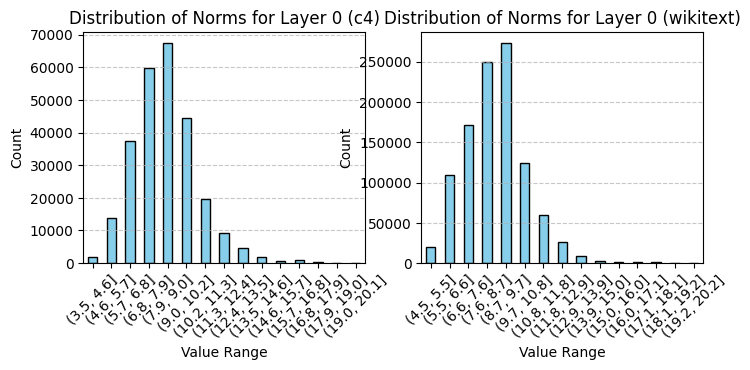

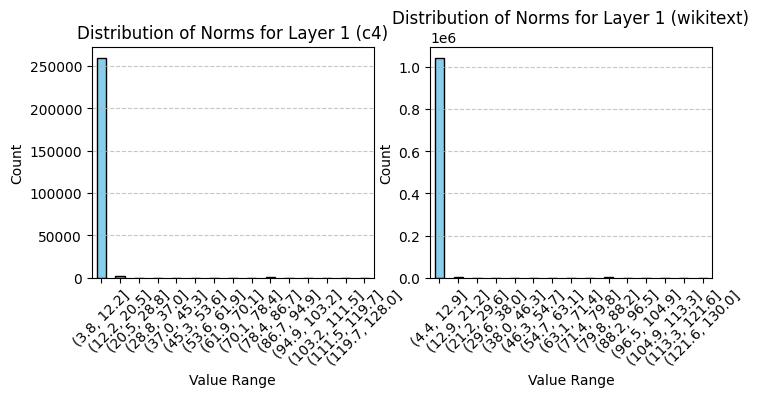

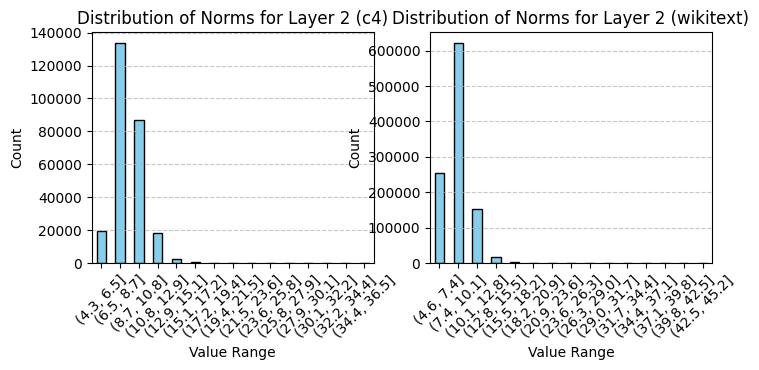

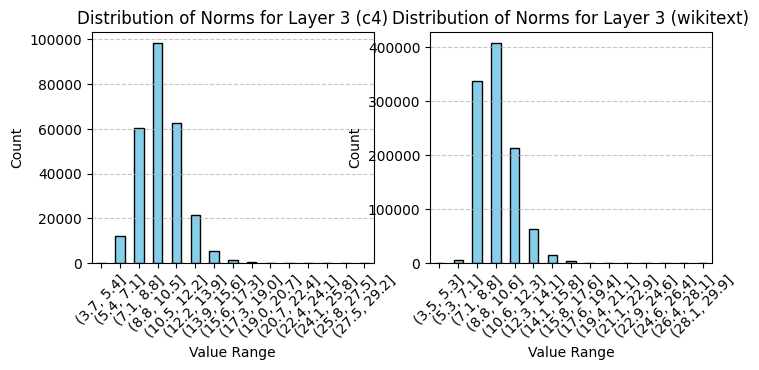

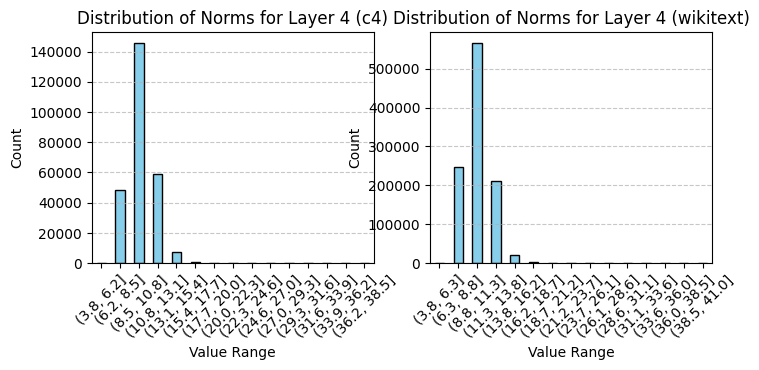

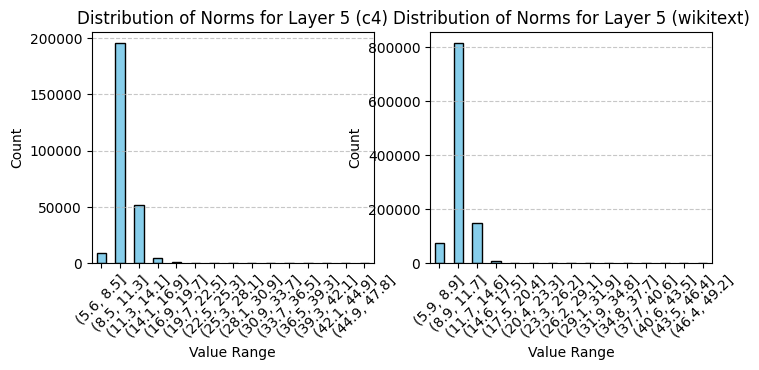

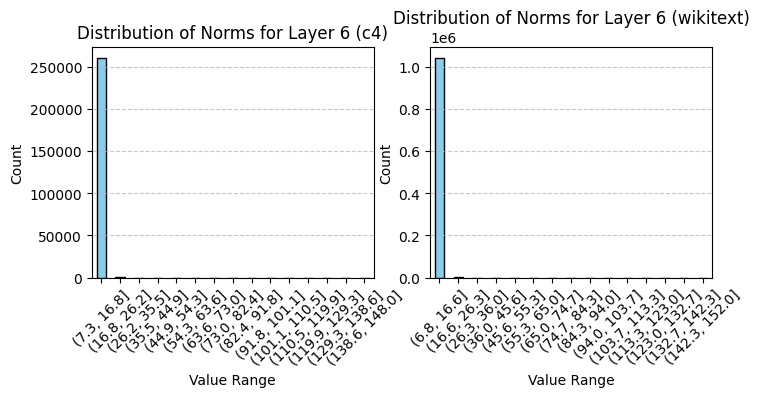

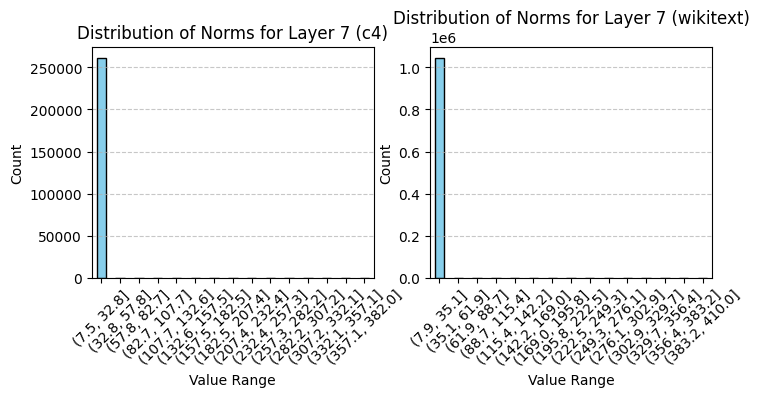

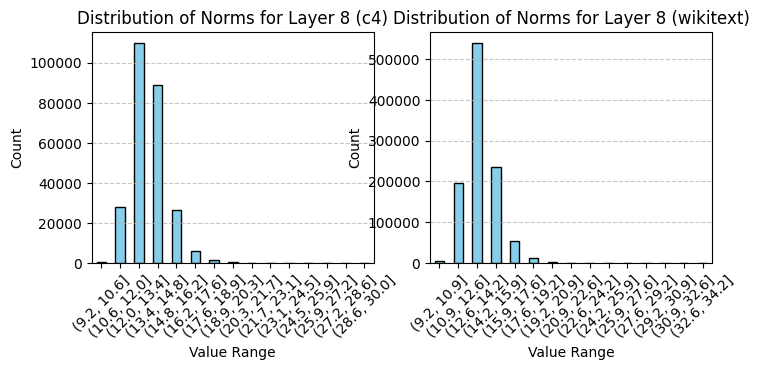

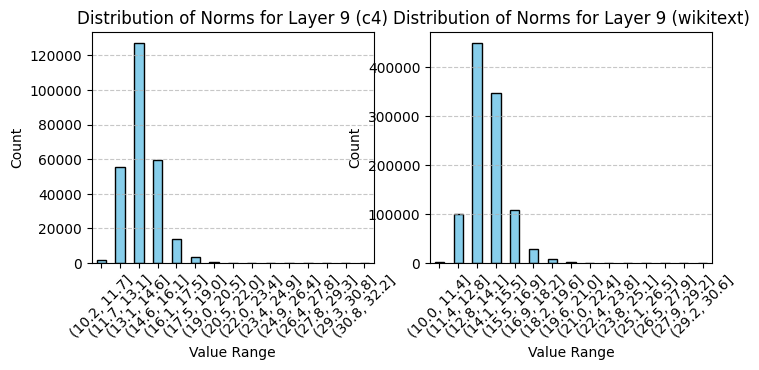

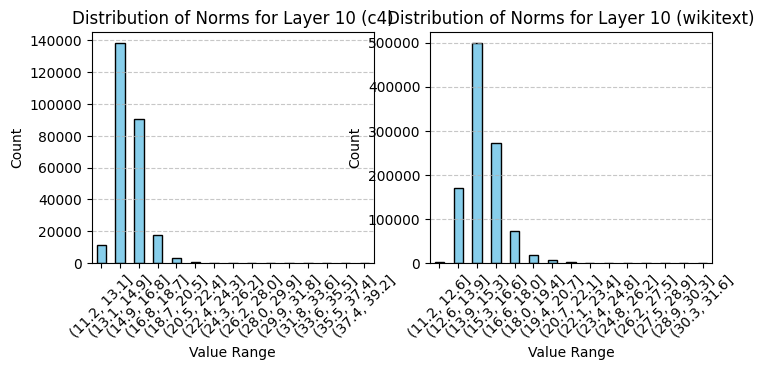

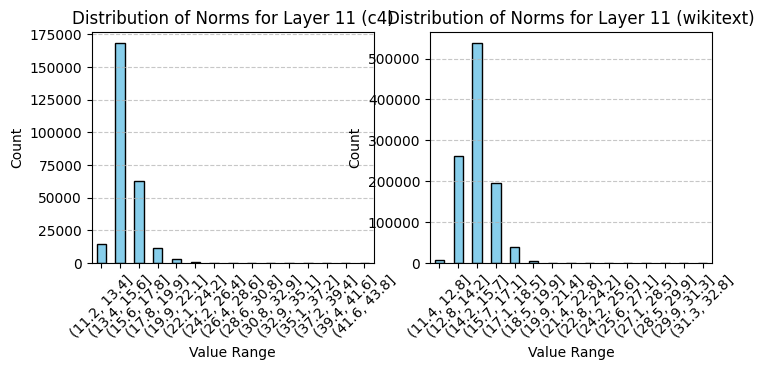

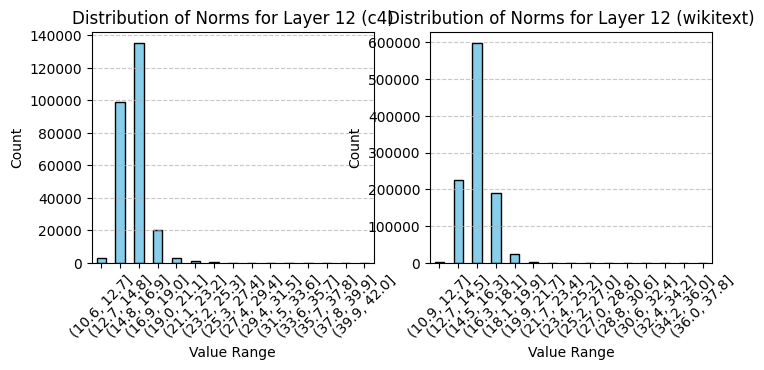

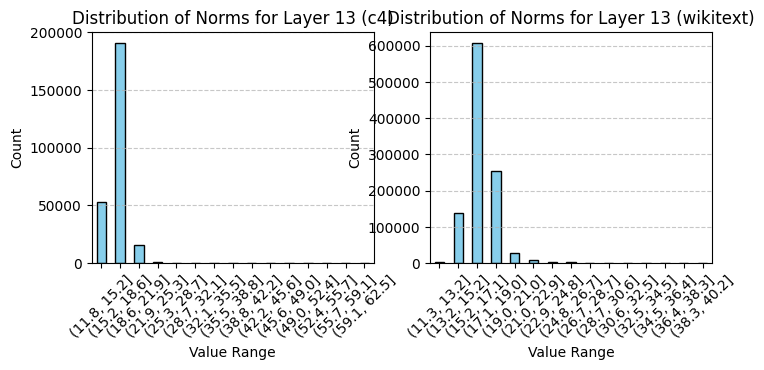

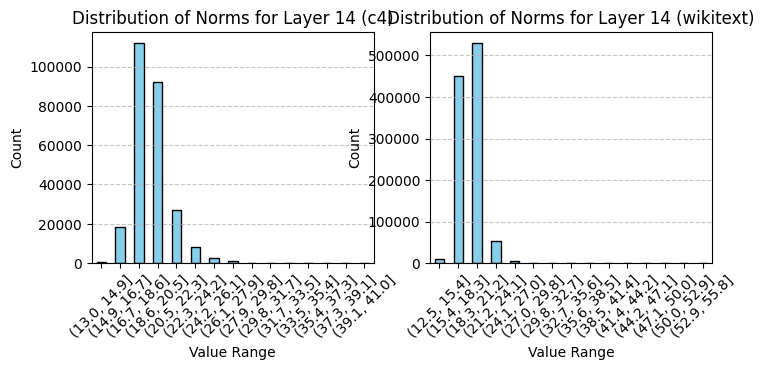

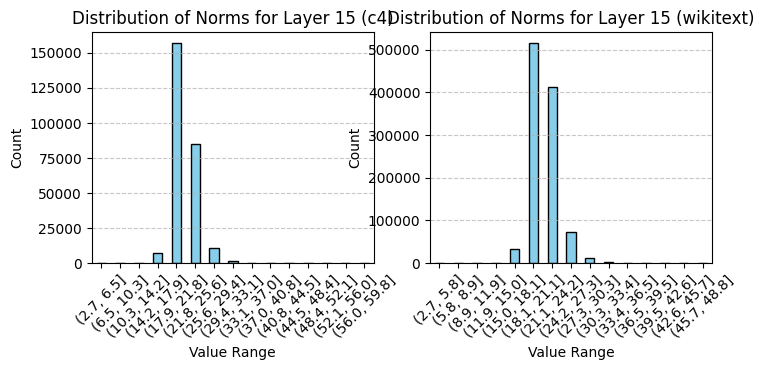

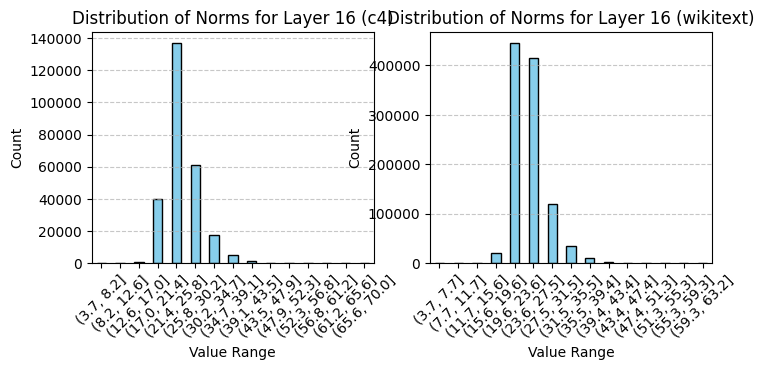

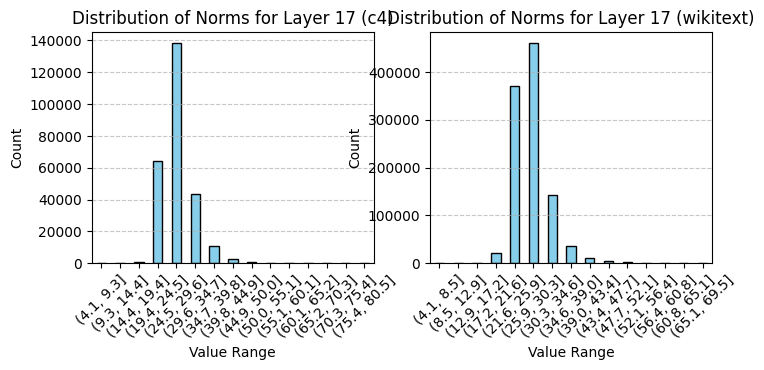

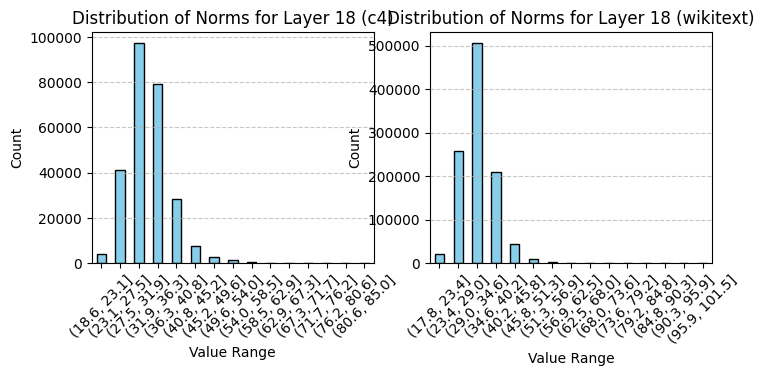

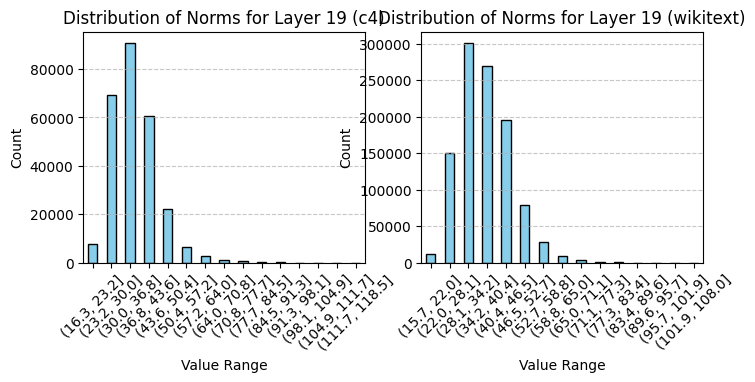

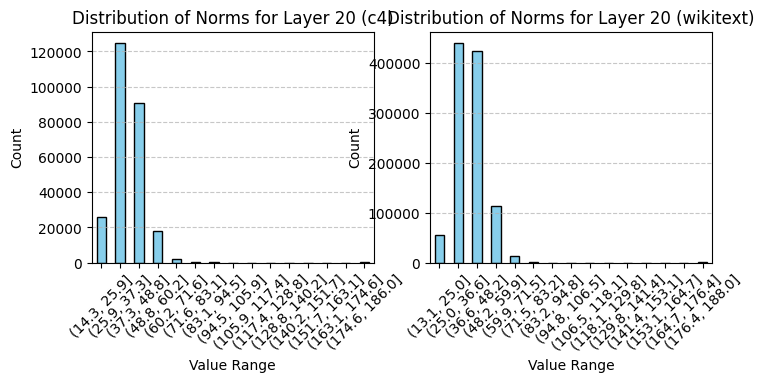

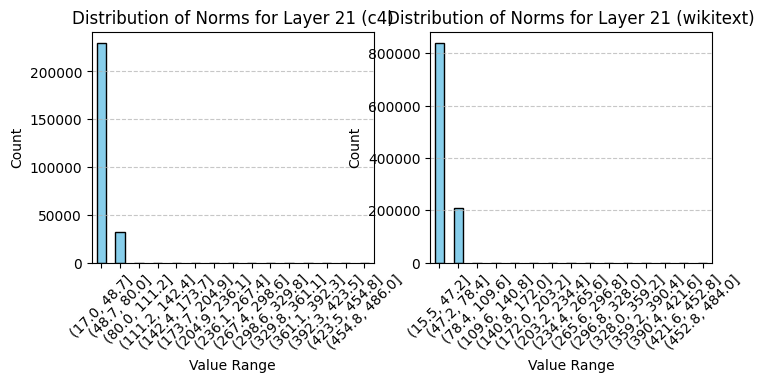

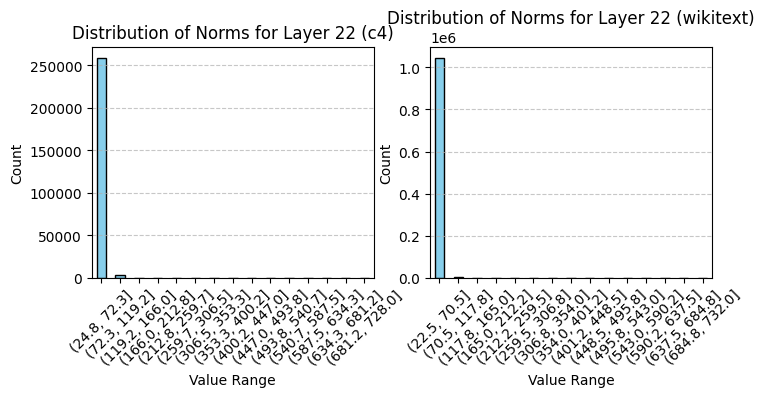

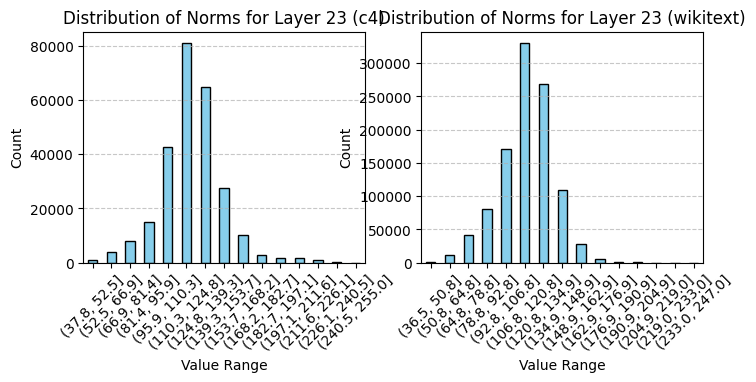

In [12]:
@torch.no_grad()
def show_mlp_rel_norm_distribution(model):
    def hook_mlp(module, inps, outs):
        outs_abs = outs.abs().detach().cpu()
        inps_abs = inps[0].abs().detach().cpu()
        module.rel_norms_L1.extend(
            rel_L1_norm(inps_abs, outs_abs).flatten().float().tolist())

    def quantiles(norms):
        return {q/100: np.quantile(norms, q/100) for q in range(10, 71, 10)}

    def dist_table(norms):
        distribution = pd.Series(norms).value_counts(bins=15, sort=False)
        table = distribution.to_frame('Count')
        table.index = [
            f"({interval.left:.1f}, {interval.right:.1f}]" for interval in table.index
        ]
        return table
    
    def show_dist(table, i, ax, dataset_name):
        table['Count'].plot(kind='bar', ax=ax, color='skyblue', edgecolor='black')
        ax.set_xlabel('Value Range')
        ax.set_ylabel('Count')
        ax.set_title(f'Distribution of Norms for Layer {i} ({dataset_name})')
        ax.grid(axis='y', linestyle='--', alpha=0.7)
        ax.tick_params(axis='x', rotation=45)

    use_cache = model.config.use_cache
    model.config.use_cache = False

    hooks = []
    for i, layer in enumerate(model.model.layers):
        mlp = layer.mlp
        mlp.rel_norms_L1 = []
        h = mlp.register_forward_hook(hook_mlp)

        for batch in dataloader:
            model(batch[0].to(DEV))
            torch.cuda.empty_cache()

        fig, ax = plt.subplots(1, 2, figsize=(8, 3))

        # mame ulozene normy pre vrstvu, z nich teraz max, min, dist a mozeme ich zmazat
        mlp.norm_stats_c4 = {'min': min(mlp.rel_norms_L1), 'max': max(mlp.rel_norms_L1)}
        mlp.norm_stats_c4['quantiles'] = quantiles(mlp.rel_norms_L1)
        
        table = dist_table(mlp.rel_norms_L1)
        mlp.norm_stats_c4['distribution'] = table.to_dict()
        show_dist(table, i, ax[0], 'c4')

        # to iste pre wikitext        
        mlp.rel_norms_L1 = []
        
        for batch in wiki_dataloader:
            model(batch[0].to(DEV))
            torch.cuda.empty_cache()

        mlp.norm_stats_wiki = {'min': min(mlp.rel_norms_L1), 'max': max(mlp.rel_norms_L1)}
        mlp.norm_stats_wiki['quantiles'] = quantiles(mlp.rel_norms_L1)
        
        table = dist_table(mlp.rel_norms_L1)
        mlp.norm_stats_wiki['distribution'] = table.to_dict()
        show_dist(table, i, ax[1], 'wikitext')
        plt.show()

        del mlp.rel_norms_L1
        model.config.use_cache = use_cache
        h.remove()
        
show_mlp_rel_norm_distribution(model)

In [13]:
layer_thresholds_stats = {
    i: {'norm_stats_c4': layer.mlp.norm_stats_c4, 
        'norm_stats_wiki': layer.mlp.norm_stats_wiki}
    for i, layer in enumerate(model.model.layers)
}

In [14]:
with open("results/layer_thresholds_stats.json", "w") as f:
    json.dump(layer_thresholds_stats, f, indent=4)

# Deleting small changes
using different thresholds for each layer separately

In [15]:
@torch.no_grad()
def test_layer_thresholds(model, i, used_data):
    def hook_threshold(module, inps, outs):
        token_norms = norm_function(inps[0].abs(), outs.abs())
        mask = token_norms >= get_threshold(module)
        ratio_over_thr.append(mask.sum().item() / mask.numel())
        return outs * mask

    def get_rel_L1_threshold(module):
        return module.threshold_rel_L1

    assert used_data in ('c4', 'wiki')

    use_cache = model.config.use_cache
    model.config.use_cache = False
    gc.collect()
    torch.cuda.empty_cache()

    norm_type, norm_function, get_threshold = 'L1', rel_L1_norm, get_rel_L1_threshold

    print('Layer', i)
    mlp = model.model.layers[i].mlp
    ppls, ratios = {}, {}
    for q in sorted(mlp.norm_stats_c4['quantiles'].keys()):
        mlp.threshold_rel_L1 = mlp.norm_stats_c4['quantiles'][q]
        ratio_over_thr = []

        h = mlp.register_forward_hook(hook_threshold)
        ppl = eval_ppl(model, wiki_testloader, device=DEV)
        h.remove()
        ratio_del = 1 - np.mean(ratio_over_thr)
        # save results
        ppls[q], ratios[q] = ppl, ratio_del
        print(f'q={q} ... ppl={ppl:.2f} ratio_del={ratio_del:.2f}')
    print()
    model.config.use_cache = use_cache
    return ppls, ratios

In [16]:
results_c4_ppl, results_c4_ratio = {}, {}
for i in range(len(model.model.layers)):
    results_c4_ppl[i], results_c4_ratio[i] = test_layer_thresholds(model, i, 'c4')

Layer 0
q=0.1 ... ppl=7.94 ratio_del=0.07
q=0.2 ... ppl=11.26 ratio_del=0.16
q=0.3 ... ppl=19.21 ratio_del=0.22
q=0.4 ... ppl=41.27 ratio_del=0.30
q=0.5 ... ppl=98.95 ratio_del=0.39
q=0.6 ... ppl=297.78 ratio_del=0.50
q=0.7 ... ppl=849.02 ratio_del=0.63

Layer 1
q=0.1 ... ppl=7.26 ratio_del=0.04
q=0.2 ... ppl=7.34 ratio_del=0.17
q=0.3 ... ppl=7.46 ratio_del=0.30
q=0.4 ... ppl=7.62 ratio_del=0.41
q=0.5 ... ppl=7.83 ratio_del=0.51
q=0.6 ... ppl=8.14 ratio_del=0.60
q=0.7 ... ppl=8.73 ratio_del=0.68

Layer 2
q=0.1 ... ppl=7.27 ratio_del=0.10
q=0.2 ... ppl=7.30 ratio_del=0.22
q=0.3 ... ppl=7.32 ratio_del=0.32
q=0.4 ... ppl=7.33 ratio_del=0.40
q=0.5 ... ppl=7.36 ratio_del=0.48
q=0.6 ... ppl=7.41 ratio_del=0.57
q=0.7 ... ppl=7.48 ratio_del=0.67

Layer 3
q=0.1 ... ppl=7.26 ratio_del=0.07
q=0.2 ... ppl=7.31 ratio_del=0.22
q=0.3 ... ppl=7.33 ratio_del=0.35
q=0.4 ... ppl=7.38 ratio_del=0.45
q=0.5 ... ppl=7.45 ratio_del=0.56
q=0.6 ... ppl=7.54 ratio_del=0.66
q=0.7 ... ppl=7.69 ratio_del=0.77

Laye

In [17]:
results_c4_ppl = pd.DataFrame(results_c4_ppl)
results_c4_ratio = pd.DataFrame(results_c4_ratio)
results_c4_ppl.index = results_c4_ratio.index = [q/100 for q in range(10, 71, 10)]
results_c4_ppl.to_csv('results/results_thr_c4_ppl.csv')
results_c4_ratio.to_csv('results/results_thr_c4_ratio.csv')

In [18]:
results_wiki_ppl, results_wiki_ratio = {}, {}
for i in range(len(model.model.layers)):
    results_wiki_ppl[i], results_wiki_ratio[i] = test_layer_thresholds(model, i, 'wiki')

Layer 0
q=0.1 ... ppl=7.94 ratio_del=0.07
q=0.2 ... ppl=11.26 ratio_del=0.16
q=0.3 ... ppl=19.21 ratio_del=0.22
q=0.4 ... ppl=41.27 ratio_del=0.30
q=0.5 ... ppl=98.95 ratio_del=0.39
q=0.6 ... ppl=297.78 ratio_del=0.50
q=0.7 ... ppl=849.02 ratio_del=0.63

Layer 1
q=0.1 ... ppl=7.26 ratio_del=0.04
q=0.2 ... ppl=7.34 ratio_del=0.17
q=0.3 ... ppl=7.46 ratio_del=0.30
q=0.4 ... ppl=7.62 ratio_del=0.41
q=0.5 ... ppl=7.83 ratio_del=0.51
q=0.6 ... ppl=8.14 ratio_del=0.60
q=0.7 ... ppl=8.73 ratio_del=0.68

Layer 2
q=0.1 ... ppl=7.27 ratio_del=0.10
q=0.2 ... ppl=7.30 ratio_del=0.22
q=0.3 ... ppl=7.32 ratio_del=0.32
q=0.4 ... ppl=7.33 ratio_del=0.40
q=0.5 ... ppl=7.36 ratio_del=0.48
q=0.6 ... ppl=7.41 ratio_del=0.57
q=0.7 ... ppl=7.48 ratio_del=0.67

Layer 3
q=0.1 ... ppl=7.26 ratio_del=0.07
q=0.2 ... ppl=7.31 ratio_del=0.22
q=0.3 ... ppl=7.33 ratio_del=0.35
q=0.4 ... ppl=7.38 ratio_del=0.45
q=0.5 ... ppl=7.45 ratio_del=0.56
q=0.6 ... ppl=7.54 ratio_del=0.66
q=0.7 ... ppl=7.69 ratio_del=0.77

Laye

In [19]:
results_wiki_ppl = pd.DataFrame(results_wiki_ppl)
results_wiki_ratio = pd.DataFrame(results_wiki_ratio)
results_wiki_ppl.index = results_wiki_ratio.index = [q/100 for q in range(10, 71, 10)]
results_wiki_ppl.to_csv('results/results_thr_wiki_ppl.csv')
results_wiki_ratio.to_csv('results/results_thr_wiki_ratio.csv')